# Report · TP3: Initialization and Regularization

**Name:** SEK Bonditkolyaney  **Course:** AI  **Date:** November 15, 2026

This report contains the follow-along parts of TP3 (Parts 0-2: initialization, L2 regularization, dropout) with the original outputs, and my solutions to the **8 assignment exercises**. Each exercise is followed by an **Answer** cell explaining what the code does and why, and discussing the results.

**Reading guide / notes**
- Variables of the assignment are called `moon_*` and `spiral_*`, so that they do not overwrite those of Parts 1-2.
- Exercise 8 includes one **extra experiment** (corrupted labels), explained in its cell, because the specified spiral data does not show overfitting.

# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [2]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [3]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [4]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


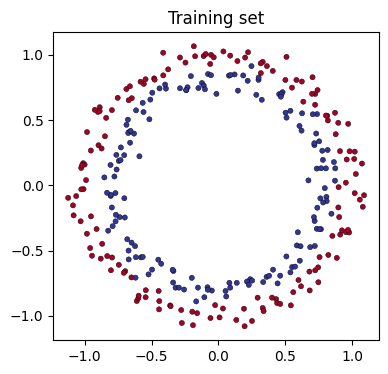

In [5]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [6]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [7]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [8]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


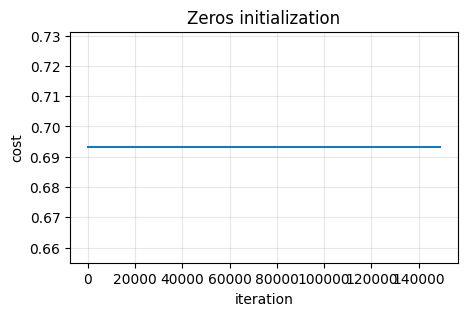

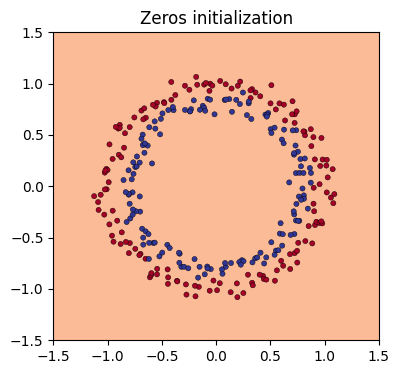

In [9]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [10]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 100
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [11]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.3742
Cost after iteration 500: 1.8181
Cost after iteration 1000: 1.7327
Cost after iteration 1500: 1.2464
Cost after iteration 2000: 1.1651
Cost after iteration 2500: 1.0781
Cost after iteration 3000: 1.0705
Cost after iteration 3500: 1.3691
Cost after iteration 4000: 0.5498
Cost after iteration 4500: 1.2791
Cost after iteration 5000: 1.3066
Cost after iteration 5500: 1.0451
Cost after iteration 6000: 1.0127
Cost after iteration 6500: 0.6397
Cost after iteration 7000: 0.9313
Cost after iteration 7500: 0.9239
Cost after iteration 8000: 0.9287
Cost after iteration 8500: 1.1548
Cost after iteration 9000: 0.6871
Cost after iteration 9500: 0.9443
Cost after iteration 10000: 0.9592
Cost after iteration 10500: 0.9330
Cost after iteration 11000: 1.2031
Cost after iteration 11500: 0.6796
Cost after iteration 12000: 0.6169
Cost after iteration 12500: 0.9332
Cost after iteration 13000: 0.6135
Cost after iteration 13500: 0.9342
Cost after iteration 14000: 0.5570
Cost afte

train accuracy 68.3% | test accuracy 65.0%


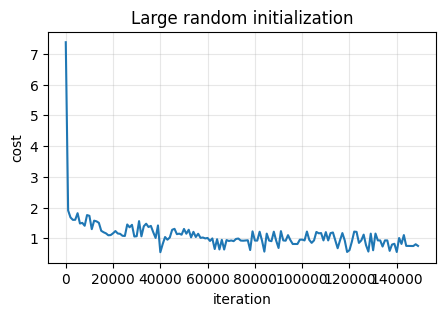

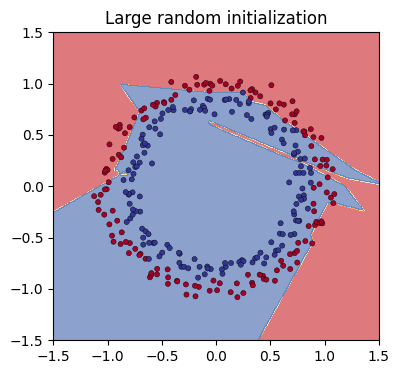

In [12]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [13]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [14]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258
Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost afte

train accuracy 97.7% | test accuracy 94.0%


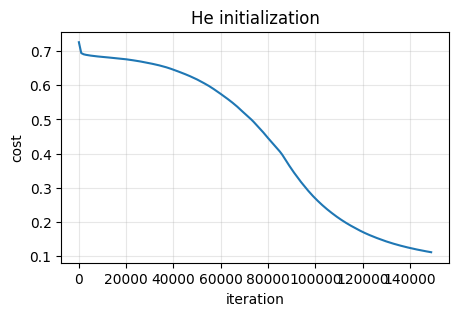

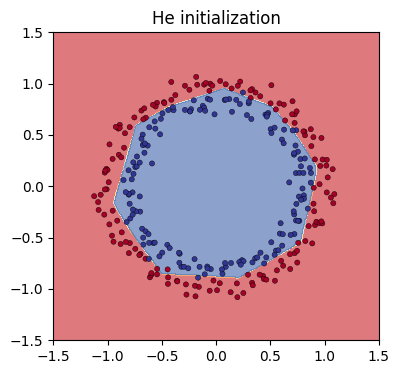

In [15]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [16]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [17]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 0.0e+00
dW1: max difference 7.5e-09 | db1: max difference 3.7e-09
dW2: max difference 3.0e-08 | db2: max difference 3.7e-09
dW3: max difference 1.9e-09 | db3: max difference 0.0e+00


In [18]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [19]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=100)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:   100 | Loss: 0.68471, Accuracy: 51.67% | Test loss: 0.68563, Test acc: 50.00%
Epoch:   200 | Loss: 0.68217, Accuracy: 51.67% | Test loss: 0.68317, Test acc: 50.00%
Epoch:   300 | Loss: 0.68055, Accuracy: 52.33% | Test loss: 0.68171, Test acc: 52.00%
Epoch:   400 | Loss: 0.67924, Accuracy: 55.33% | Test loss: 0.68061, Test acc: 54.00%
Epoch:   500 | Loss: 0.67802, Accuracy: 55.33% | Test loss: 0.67959, Test acc: 54.00%
Epoch:   600 | Loss: 0.67683, Accuracy: 56.67% | Test loss: 0.67859, Test acc: 57.00%
Epoch:   700 | Loss: 0.67562, Accuracy: 57.33% | Test loss: 0.67753, Test acc: 58.00%
Epoch:   800 | Loss: 0.67436, Accuracy: 57.33% | Test loss: 0.67642, Test acc: 61.00%
Epoch:   900 | Loss: 0.67305, Accuracy: 58.00% | Test loss: 0.67530, Test acc: 60.00%
Epoch:  1000 | Loss: 0.67164, Accuracy: 58.67% | Test loss: 0.67409, Test acc: 60.00%
Epoch:  1100 | Loss: 0.67021, Accuracy: 59.00% | Test 

initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


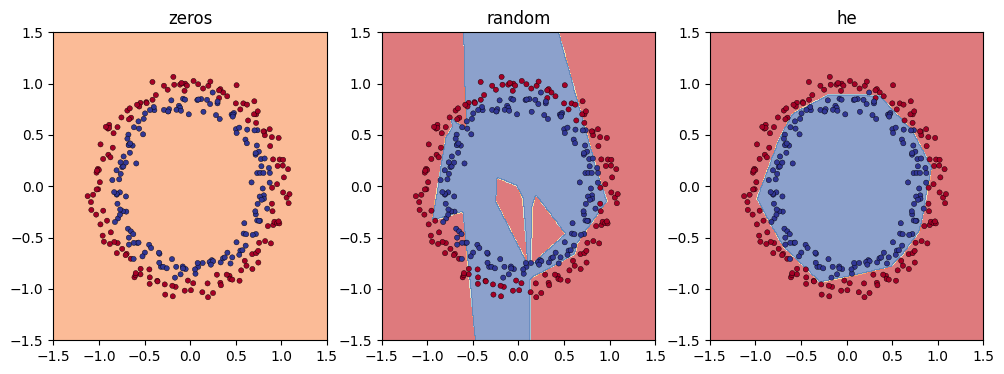

In [20]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [21]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


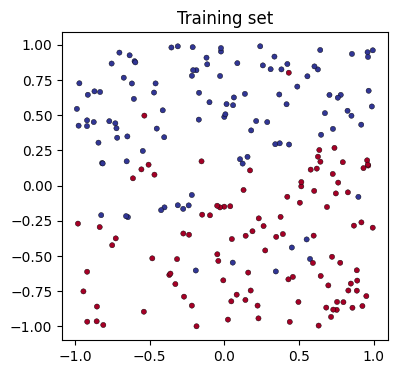

In [22]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 1000: 0.2248
Cost after iteration 2000: 0.2015
Cost after iteration 3000: 0.1924
Cost after iteration 4000: 0.1659
Cost after iteration 5000: 0.1523
Cost after iteration 6000: 0.1447
Cost after iteration 7000: 0.1435
Cost after iteration 8000: 0.1337
Cost after iteration 9000: 0.1310
Cost after iteration 10000: 0.1380
Cost after iteration 11000: 0.1298
Cost after iteration 12000: 0.1247
Cost after iteration 13000: 0.1217
Cost after iteration 14000: 0.1181
Cost after iteration 15000: 0.1123
Cost after iteration 16000: 0.1021
Cost after iteration 17000: 0.1512
Cost after iteration 18000: 0.0802
Cost after iteration 19000: 0.1786
Cost after iteration 20000: 0.0629
Cost after iteration 21000: 0.0906
Cost after iteration 22000: 0.0693
Cost after iteration 23000: 0.0529
Cost after iteration 24000: 0.0493
Cost after iteration 25000: 0.0583
Cost after iteration 26000: 0.0691
Cost after iteration 27000: 0.1152
Cost after iteration 28000: 0.037

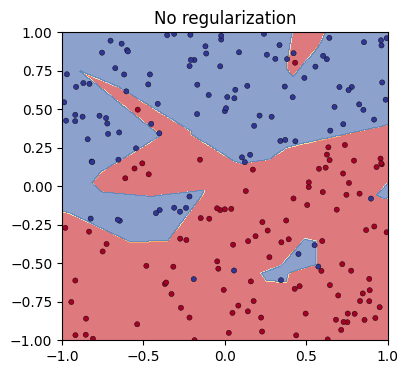

In [23]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=1000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 1000: 0.2991
Cost after iteration 2000: 0.2953
Cost after iteration 3000: 0.2931
Cost after iteration 4000: 0.2918
Cost after iteration 5000: 0.2906
Cost after iteration 6000: 0.2894
Cost after iteration 7000: 0.2889
Cost after iteration 8000: 0.2883
Cost after iteration 9000: 0.2881
Cost after iteration 10000: 0.2880
Cost after iteration 11000: 0.2879
Cost after iteration 12000: 0.2880
Cost after iteration 13000: 0.2879
Cost after iteration 14000: 0.2879
Cost after iteration 15000: 0.2879
Cost after iteration 16000: 0.2878
Cost after iteration 17000: 0.2878
Cost after iteration 18000: 0.2878
Cost after iteration 19000: 0.2879
Cost after iteration 20000: 0.2878
Cost after iteration 21000: 0.2878
Cost after iteration 22000: 0.2882
Cost after iteration 23000: 0.2878
Cost after iteration 24000: 0.2878
Cost after iteration 25000: 0.2877
Cost after iteration 26000: 0.2878
Cost after iteration 27000: 0.2877
Cost after iteration 28000: 0.288

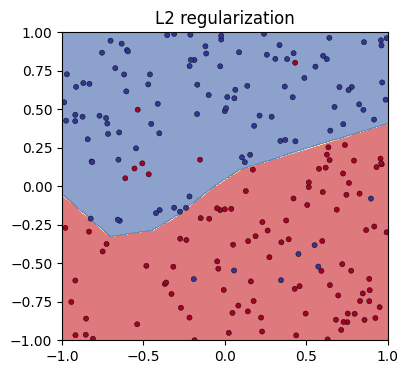

In [24]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 1000: 0.3121
Cost after iteration 2000: 0.2387
Cost after iteration 3000: 0.2588
Cost after iteration 4000: 0.2644
Cost after iteration 5000: 0.2714
Cost after iteration 6000: 0.2174
Cost after iteration 7000: 0.2323
Cost after iteration 8000: 0.1942
Cost after iteration 9000: 0.2002
Cost after iteration 10000: 0.2032
Cost after iteration 11000: 0.2299
Cost after iteration 12000: 0.2047
Cost after iteration 13000: 0.2782
Cost after iteration 14000: 0.2127
Cost after iteration 15000: 0.1875
Cost after iteration 16000: 0.1976
Cost after iteration 17000: 0.2346
Cost after iteration 18000: 0.2299
Cost after iteration 19000: 0.1991
Cost after iteration 20000: 0.1904
Cost after iteration 21000: 0.1669
Cost after iteration 22000: 0.2021
Cost after iteration 23000: 0.1688
Cost after iteration 24000: 0.1826
Cost after iteration 25000: 0.2579
Cost after iteration 26000: 0.2124
Cost after iteration 27000: 0.2197
Cost after iteration 28000: 0.185

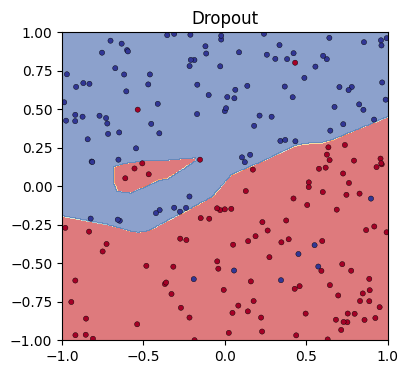

In [25]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [26]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [27]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [28]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 96.7% | test accuracy 91.0%
PyTorch | L2, lambda = 0.7: train accuracy 91.9% | test accuracy 94.0%
PyTorch | dropout, keep_prob = 0.86: train accuracy 96.7% | test accuracy 89.5%


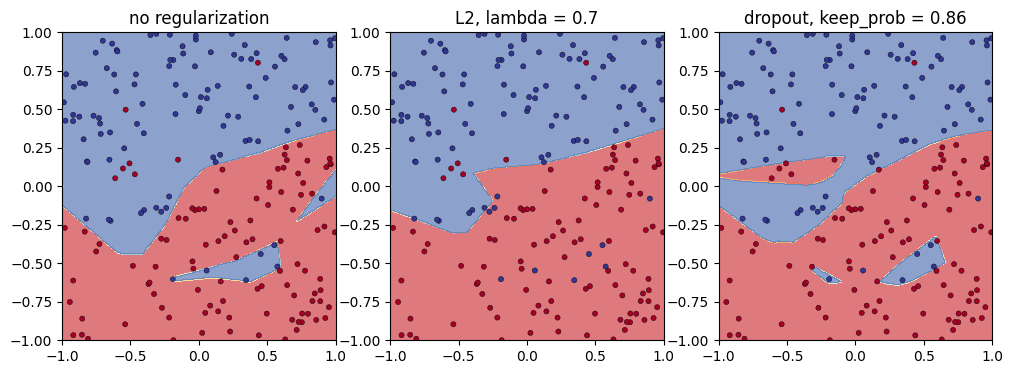

In [29]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [30]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               96.7%    85.0%      96.7%    91.0%
L2, lambda = 0.7                93.4%    95.0%      91.9%    94.0%
dropout, keep_prob = 0.86       95.3%    94.0%      96.7%    89.5%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

train_X (800, 2) | train_Y (800, 1) | test_X (200, 2) | test_Y (200, 1)
fraction of class 1 in the training set: 0.5


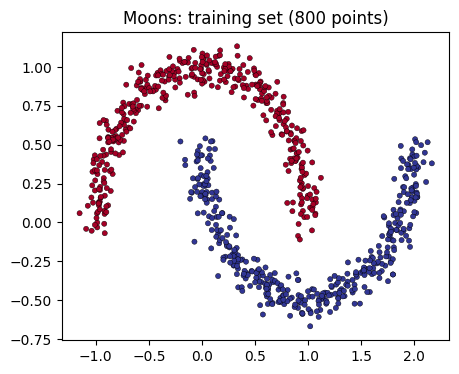

In [31]:
# Exercise 1: the moons dataset
X_moons, y_moons = make_moons(n_samples=1000, noise=0.07, random_state=42)

# NumPy arrays -> float32 tensors; labels get shape (m, 1)
X_moons = torch.tensor(X_moons, dtype=torch.float32)
y_moons = torch.tensor(y_moons, dtype=torch.float32).reshape(-1, 1)

# 80% training / 20% test
moon_train_X, moon_test_X, moon_train_Y, moon_test_Y = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=42)
print("train_X", tuple(moon_train_X.shape), "| train_Y", tuple(moon_train_Y.shape),
      "| test_X", tuple(moon_test_X.shape), "| test_Y", tuple(moon_test_Y.shape))
print("fraction of class 1 in the training set:", round(moon_train_Y.mean().item(), 3))

plt.figure(figsize=(5, 4))
plt.scatter(moon_train_X[:, 0], moon_train_X[:, 1], c=moon_train_Y.flatten(), s=14,
            cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Moons: training set (800 points)"); plt.show()

**Answer.** The goal of this first step is to get the data ready in the exact form PyTorch needs.

- `make_moons` creates 1000 points forming two interleaving half-circles (the "moons"), one per class (0 or 1). `noise=0.07` adds a small random jitter so the points are not perfectly on the curves, and `random_state=42` makes the result identical on every run.
- scikit-learn returns NumPy arrays, so we convert them to **tensors** (PyTorch's array type). We use `float32` because that is the number type neural-network layers expect.
- The labels get the shape `(m, 1)`, i.e. one column, to match the model's single output per example (`-1` in `reshape` means "figure this dimension out yourself").
- `train_test_split` shuffles the data and keeps **80% (800 points) for training** and **20% (200 points) for testing**. The model learns only from the training set; the test set stays hidden and is used at the end to check that the model works on data it has never seen.

The two classes are balanced (50% / 50%) and clearly curved: **no straight line can separate them**, so the model will need non-linear activation functions.

### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [32]:
# Exercise 2: a model for the moons
class MoonModel(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.layer_1 = nn.Linear(2, hidden)        # 2 input features -> `hidden` units
        self.layer_2 = nn.Linear(hidden, hidden)
        self.layer_3 = nn.Linear(hidden, 1)        # ONE output: the logit
        self.relu = nn.ReLU()                      # the non-linearity

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def he_init(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")   # He initialization
            nn.init.zeros_(layer.bias)                                   # zero biases
    return model

torch.manual_seed(42)
moon_model = he_init(MoonModel(hidden=16)).to(device)
print(moon_model)
n_params = sum(p.numel() for p in moon_model.parameters())
print("Number of parameters:", n_params)
for name, p in moon_model.named_parameters():
    print(f"  {name:16s} {tuple(p.shape)!s:10s} {p.numel():4d}")

MoonModel(
  (layer_1): Linear(in_features=2, out_features=16, bias=True)
  (layer_2): Linear(in_features=16, out_features=16, bias=True)
  (layer_3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)
Number of parameters: 337
  layer_1.weight   (16, 2)      32
  layer_1.bias     (16,)        16
  layer_2.weight   (16, 16)    256
  layer_2.bias     (16,)        16
  layer_3.weight   (1, 16)      16
  layer_3.bias     (1,)          1


**Answer.** The model has three `nn.Linear` layers, with ReLU between them, and **one output (a logit)**.

- **Subclassing `nn.Module`:** `__init__` declares the layers, `forward` describes how data flows through them. PyTorch derives the backward pass (gradients) automatically.
- **Why non-linear activations?** Without ReLU, stacking linear layers is equivalent to a single linear layer, which can only draw a straight line. ReLU lets the model bend its decision boundary around the moons.
- **Why one logit?** The task has two classes, so a single raw score is enough: after a sigmoid it becomes the probability of class 1.
- **He initialization(a technique for setting the starting weights of a neural network before training begins):** weights are drawn at random with a standard deviation of $\sqrt{2/n_{in}}$, which keeps the size of the signal stable from layer to layer in ReLU networks (see Part 1). Biases start at zero. `nn.init.kaiming_normal_` implements this ("Kaiming" is He's first name).

**Parameter count (337):** layer 1: $2\times16+16 = 48$; layer 2: $16\times16+16 = 272$; layer 3: $16\times1+1 = 17$; total $48+272+17 = 337$. This matches the printout above (a layer with $n_{in}$ inputs and $n_{out}$ outputs has $n_{in}\,n_{out}$ weights plus $n_{out}$ biases).

### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [33]:
# Exercise 3: loss and optimizer
loss_fn_moons = nn.BCEWithLogitsLoss()                                   # sigmoid + binary cross-entropy, takes LOGITS
optimizer = torch.optim.SGD(moon_model.parameters(), lr=0.1)           # SGD on the whole training set = batch gradient descent
print(loss_fn_moons)
print(optimizer)

BCEWithLogitsLoss()
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


**Answer.**

- **Loss:** `nn.BCEWithLogitsLoss()`, binary cross-entropy for two-class problems. It takes the **raw logits** and applies the sigmoid itself.
- **Optimizer:** `torch.optim.SGD` with learning rate `lr`. Since our loop gives it the whole training set at every step, it performs **batch gradient descent**: each step moves every weight a little in the direction that lowers the loss, $w \leftarrow w - \text{lr}\cdot\frac{\partial J}{\partial w}$.

**Why `BCEWithLogitsLoss` rather than `nn.Sigmoid()` + `nn.BCELoss()`?** It fuses the sigmoid and the loss into one numerically stable computation (using the log-sum-exp trick), whereas a separate sigmoid can saturate to exactly 0 or 1, making $\log(0)$ blow up to infinity or `NaN`.

### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [34]:
# Exercise 4, attempt 1: learning rate 0.01
torch.manual_seed(42)                                           # same random start every time
moon_model = he_init(MoonModel(hidden=16)).to(device)
optimizer = torch.optim.SGD(moon_model.parameters(), lr=0.01)

moon_model = train_and_test(moon_model, loss_fn_moons, optimizer,
                            moon_train_X, moon_train_Y, moon_test_X, moon_test_Y,
                            epochs=1000, print_every=100)
print(f"\nFinal | train accuracy {accuracy(moon_model, moon_train_X, moon_train_Y):.1f}% "
      f"| test accuracy {accuracy(moon_model, moon_test_X, moon_test_Y):.1f}%")

Epoch:     0 | Loss: 0.77541, Accuracy: 19.12% | Test loss: 0.76631, Test acc: 18.50%
Epoch:   100 | Loss: 0.55509, Accuracy: 75.00% | Test loss: 0.57004, Test acc: 69.00%
Epoch:   200 | Loss: 0.45096, Accuracy: 81.12% | Test loss: 0.46861, Test acc: 77.50%
Epoch:   300 | Loss: 0.38270, Accuracy: 83.75% | Test loss: 0.39987, Test acc: 80.50%
Epoch:   400 | Loss: 0.33903, Accuracy: 85.25% | Test loss: 0.35427, Test acc: 82.00%
Epoch:   500 | Loss: 0.31080, Accuracy: 86.00% | Test loss: 0.32346, Test acc: 83.50%
Epoch:   600 | Loss: 0.29118, Accuracy: 86.38% | Test loss: 0.30113, Test acc: 85.50%
Epoch:   700 | Loss: 0.27647, Accuracy: 86.62% | Test loss: 0.28394, Test acc: 85.50%
Epoch:   800 | Loss: 0.26488, Accuracy: 87.38% | Test loss: 0.27018, Test acc: 86.50%
Epoch:   900 | Loss: 0.25534, Accuracy: 87.50% | Test loss: 0.25897, Test acc: 86.50%

Final | train accuracy 87.6% | test accuracy 86.5%


In [35]:
# Exercise 4, attempt 2: learning rate 0.1 (the only change)
torch.manual_seed(42)
moon_model = he_init(MoonModel(hidden=16)).to(device)
optimizer = torch.optim.SGD(moon_model.parameters(), lr=0.1)    # was 0.01

moon_model = train_and_test(moon_model, loss_fn_moons, optimizer,
                            moon_train_X, moon_train_Y, moon_test_X, moon_test_Y,
                            epochs=1000, print_every=100)
print(f"\nFinal | train accuracy {accuracy(moon_model, moon_train_X, moon_train_Y):.1f}% "
      f"| test accuracy {accuracy(moon_model, moon_test_X, moon_test_Y):.1f}%")

Epoch:     0 | Loss: 0.77541, Accuracy: 19.12% | Test loss: 0.72838, Test acc: 31.00%
Epoch:   100 | Loss: 0.24720, Accuracy: 87.62% | Test loss: 0.24894, Test acc: 86.50%
Epoch:   200 | Loss: 0.18896, Accuracy: 91.88% | Test loss: 0.18768, Test acc: 91.00%
Epoch:   300 | Loss: 0.13876, Accuracy: 94.00% | Test loss: 0.13247, Test acc: 94.50%
Epoch:   400 | Loss: 0.08973, Accuracy: 97.38% | Test loss: 0.07996, Test acc: 98.00%
Epoch:   500 | Loss: 0.05709, Accuracy: 98.88% | Test loss: 0.04758, Test acc: 99.50%
Epoch:   600 | Loss: 0.03838, Accuracy: 99.38% | Test loss: 0.03165, Test acc: 99.50%
Epoch:   700 | Loss: 0.02769, Accuracy: 99.88% | Test loss: 0.02223, Test acc: 100.00%
Epoch:   800 | Loss: 0.02100, Accuracy: 100.00% | Test loss: 0.01648, Test acc: 100.00%
Epoch:   900 | Loss: 0.01661, Accuracy: 100.00% | Test loss: 0.01263, Test acc: 100.00%

Final | train accuracy 100.0% | test accuracy 100.0%


**Answer.** We reuse `train_and_test` from Part 1. Each epoch (one pass over the training set) does: (1) forward pass to get logits; (2) loss; (3) `zero_grad()`, because PyTorch *adds* new gradients to old ones; (4) `loss.backward()` computes all gradients; (5) `optimizer.step()` updates the weights. Then, without learning, the model is evaluated on the test set (`model.eval()` + `torch.inference_mode()`). Loss and accuracy of both sets are printed every 100 epochs.

**Attempt 1: `lr = 0.01`, 16 hidden units, 1000 epochs.** Final result: **87.6% train / 86.5% test**, below the 96% target. The loss was still decreasing steadily at epoch 900, so the model was not stuck or too small: it was **learning too slowly** (underfitting because the steps are tiny and 1000 epochs is not enough to reach the bottom).

**What I changed:** I increased the **learning rate from 0.01 to 0.1**. Larger steps cover the same distance faster. The other options (more epochs, more hidden units) would also work, but more epochs cost time, and the network already has enough capacity.

**Attempt 2: `lr = 0.1`.** The loss drops much faster (0.25 at epoch 100 instead of 0.55), accuracy passes 96% after about 400 epochs, and the final result is **100% train / 100% test** (final training loss ≈ 0.017). Train and test accuracies stay close together throughout, so there is no sign of overfitting.

*Note: a learning rate that is too large would make the loss jump around instead of decreasing, so it should be increased gradually.*

### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

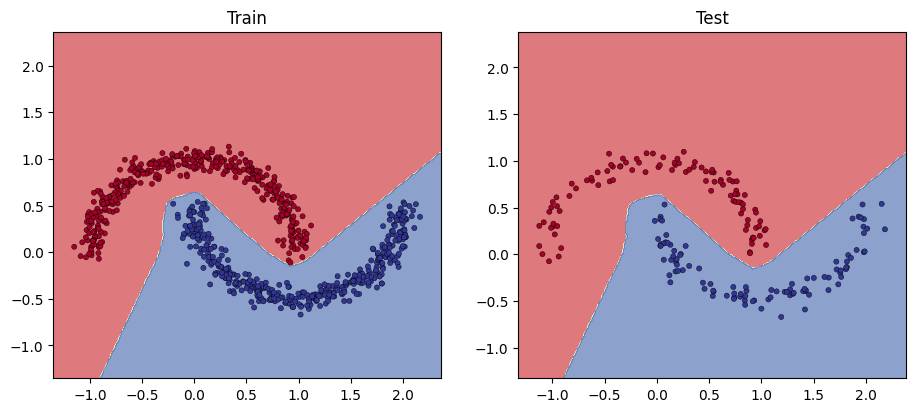

In [36]:
# Exercise 5: decision boundaries of the trained model
plt.figure(figsize=(11, 4.5))
plt.subplot(1, 2, 1); plt.title("Train")
plot_decision_boundary(moon_model, moon_train_X, moon_train_Y)
plt.subplot(1, 2, 2); plt.title("Test")
plot_decision_boundary(moon_model, moon_test_X, moon_test_Y)
plt.show()

**Answer.** `plot_decision_boundary` evaluates the model on a fine grid covering the whole plane and colors each grid point by the predicted class, so the border between the two colors is the decision boundary.

The boundary is a smooth-ish curve that passes **between the two moons** and wraps around the tip of the blue moon, on both the training set and the test set. All test points lie in the correct colored region, which agrees with the 100% test accuracy. Its slightly angular shape comes from ReLU: the network computes a piecewise-linear function. Far away from the data the boundary continues as straight lines, because the model has seen no points there and just extends what it learned.

### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

max |tanh_by_hand - torch.tanh| on linspace(-5, 5, 101): 1.19e-07


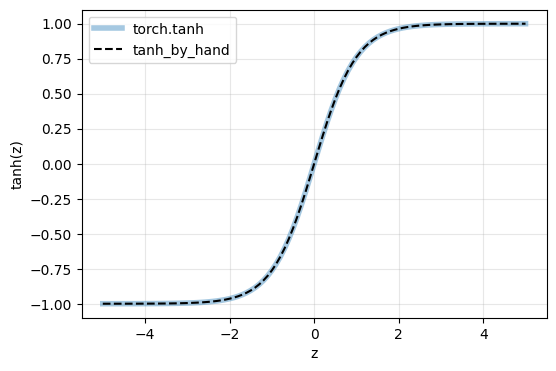

In [37]:
# Exercise 6: tanh by hand
def tanh_by_hand(z):
    return (torch.exp(z) - torch.exp(-z)) / (torch.exp(z) + torch.exp(-z))

z = torch.linspace(-5, 5, 101)
diff = (tanh_by_hand(z) - torch.tanh(z)).abs().max()
print(f"max |tanh_by_hand - torch.tanh| on linspace(-5, 5, 101): {diff.item():.2e}")

plt.figure(figsize=(6, 4))
plt.plot(z, torch.tanh(z), label="torch.tanh", linewidth=4, alpha=0.4)
plt.plot(z, tanh_by_hand(z), "--", label="tanh_by_hand", color="k")
plt.xlabel("z"); plt.ylabel("tanh(z)"); plt.grid(alpha=0.3); plt.legend(); plt.show()

In [38]:
# Optional: large inputs
big = torch.tensor([100.0, -100.0, 50.0])
print("exp(100)        =", torch.exp(torch.tensor(100.0)).item())
print("tanh_by_hand    =", tanh_by_hand(big))
print("torch.tanh      =", torch.tanh(big))

def tanh_stable(z):
    return 2 * torch.sigmoid(2 * z) - 1

print("tanh_stable     =", tanh_stable(big))
print(f"max difference of tanh_stable with torch.tanh on linspace(-5, 5, 101): "
      f"{(tanh_stable(z) - torch.tanh(z)).abs().max().item():.2e}")

exp(100)        = inf
tanh_by_hand    = tensor([nan, nan, 1.])
torch.tanh      = tensor([ 1., -1.,  1.])
tanh_stable     = tensor([ 1., -1.,  1.])
max difference of tanh_stable with torch.tanh on linspace(-5, 5, 101): 1.19e-07


**Answer.** $\tanh(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ is an activation function similar to the sigmoid but with outputs between $-1$ and $1$, (sigmoid's output is between 0 and 1). The hand-written version agrees with `torch.tanh` to about $1.2\times10^{-7}$, which is the rounding precision of `float32`, and the two curves are indistinguishable in the plot.

**Optional: what happens for $z=100$?** $e^{100}\approx 2.7\times10^{43}$ is larger than the biggest `float32` number ($\approx3.4\times10^{38}$), so `torch.exp(100)` overflows to `inf`. The formula then computes $\infty/\infty$, which is `NaN` (not a number): the function returns `nan` for $z=\pm100$ (even though the true answer is $\pm1$), and a single `NaN` in a network would contaminate every later computation.

**The safer version.** Using $\tanh(z)=2\sigma(2z)-1$ gives the same values (same precision as before on $[-5,5]$), and for $z=\pm100$ it correctly returns $\pm1$. `torch.sigmoid` is implemented to be numerically stable: it never needs to compute an exponential of a large positive number, and for large $|z|$ it simply saturates to 0 or 1.

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

train_X (240, 2) | train_y (240,) | test_X (60, 2) | test_y (60,)


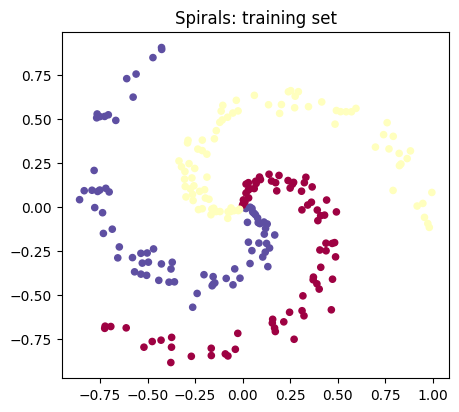

In [39]:
# Exercise 7: spiral data (CS231n code)
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j

# tensors: X float32 (m, 2); y long (m,)  -- CrossEntropyLoss wants class indices
X_sp = torch.tensor(X, dtype=torch.float32)
y_sp = torch.tensor(y, dtype=torch.long)
spiral_train_X, spiral_test_X, spiral_train_y, spiral_test_y = train_test_split(
    X_sp, y_sp, test_size=0.2, random_state=42)
print("train_X", tuple(spiral_train_X.shape), "| train_y", tuple(spiral_train_y.shape),
      "| test_X", tuple(spiral_test_X.shape), "| test_y", tuple(spiral_test_y.shape))

plt.figure(figsize=(5, 4.5))
plt.scatter(spiral_train_X[:, 0], spiral_train_X[:, 1], c=spiral_train_y, s=20, cmap=plt.cm.Spectral)
plt.title("Spirals: training set"); plt.show()

**Answer (data).** Three spiral arms (one per class), 100 points each. The labels are the integers 0, 1, 2. For the multi-class case, `X` is `float32` of shape $(m,2)$ and `y` is **`long`** of shape $(m,)$: `nn.CrossEntropyLoss` expects **class indices**, not one-hot vectors and not a column. The 80/20 split gives 240 training and 60 test points.

In [40]:
# model: 2 -> 32 -> 32 -> 3 logits
class SpiralModel(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 3))                  # 3 logits, one per class
    def forward(self, x):
        return self.net(x)

# training and testing loop for the multi-class case
def train_and_test_multiclass(model, loss_fn, optimizer, X_train, y_train, X_test, y_test,
                              epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    history = {"train_loss": [], "test_loss": []}
    for epoch in range(epochs):
        ### Training
        model.train()
        logits = model(X_train)                                  # 1. forward pass: (m, 3) logits
        loss = loss_fn(logits, y_train)                          # 2. softmax + cross-entropy
        acc = accuracy_fn(y_train, logits.argmax(dim=1))         #    predicted class = argmax
        optimizer.zero_grad()                                    # 3. zero the gradients
        loss.backward()                                          # 4. backpropagation
        optimizer.step()                                         # 5. update the parameters
        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_test, test_logits.argmax(dim=1))
        history["train_loss"].append(loss.item()); history["test_loss"].append(test_loss.item())
        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model, history

torch.manual_seed(42)
spiral_model = SpiralModel(hidden=32).to(device)
print(spiral_model)
print("Number of parameters:", sum(p.numel() for p in spiral_model.parameters()))

loss_fn_sp = nn.CrossEntropyLoss()
optimizer_sp = torch.optim.Adam(spiral_model.parameters(), lr=0.01)
spiral_model, _ = train_and_test_multiclass(spiral_model, loss_fn_sp, optimizer_sp,
                                            spiral_train_X, spiral_train_y, spiral_test_X, spiral_test_y,
                                            epochs=1000, print_every=100)
print(f"\nFinal | train accuracy {accuracy(spiral_model, spiral_train_X, spiral_train_y):.1f}% "
      f"| test accuracy {accuracy(spiral_model, spiral_test_X, spiral_test_y):.1f}%")

SpiralModel(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)
Number of parameters: 1251
Epoch:     0 | Loss: 1.10401, Accuracy: 35.00% | Test loss: 1.09031, Test acc: 26.67%
Epoch:   100 | Loss: 0.06803, Accuracy: 99.17% | Test loss: 0.03968, Test acc: 100.00%
Epoch:   200 | Loss: 0.03402, Accuracy: 99.17% | Test loss: 0.00789, Test acc: 100.00%
Epoch:   300 | Loss: 0.02522, Accuracy: 99.17% | Test loss: 0.00241, Test acc: 100.00%
Epoch:   400 | Loss: 0.02091, Accuracy: 99.17% | Test loss: 0.00087, Test acc: 100.00%
Epoch:   500 | Loss: 0.01852, Accuracy: 99.17% | Test loss: 0.00037, Test acc: 100.00%
Epoch:   600 | Loss: 0.01713, Accuracy: 99.17% | Test loss: 0.00019, Test acc: 100.00%
Epoch:   700 | Loss: 0.01611, Accuracy: 99.17% | Test loss: 0.00015, Test acc: 100.00%
Epoch:   800 | Loss: 0.01560

**Answer (model, loss, loop).**

- **Model:** `2 → 32 → ReLU → 32 → ReLU → 3`, 1251 parameters. It outputs **3 logits**, one per class. The network needs hidden layers with ReLU because the classes are interleaved spirals that no straight line can separate.
- **Loss:** `nn.CrossEntropyLoss()` is **softmax + cross-entropy** in one: the softmax turns the 3 logits into 3 probabilities that sum to 1, and the loss is $-\log$ of the probability given to the correct class. Like `BCEWithLogitsLoss`, it takes raw logits.
- **Optimizer:** **Adam** (`lr = 0.01`), a gradient-descent variant that adapts the step size of each weight. It converges faster than plain SGD on this problem.
- **Loop:** identical to the binary one, except that the predicted class is the `argmax` of the logits (the class with the highest score) instead of "sigmoid then round".

**Result:** **99.2% train / 100% test accuracy**, above the 95% target. Only 2 of the 240 training points are misclassified (noisy points where the spirals overlap), and all 60 test points are correct.

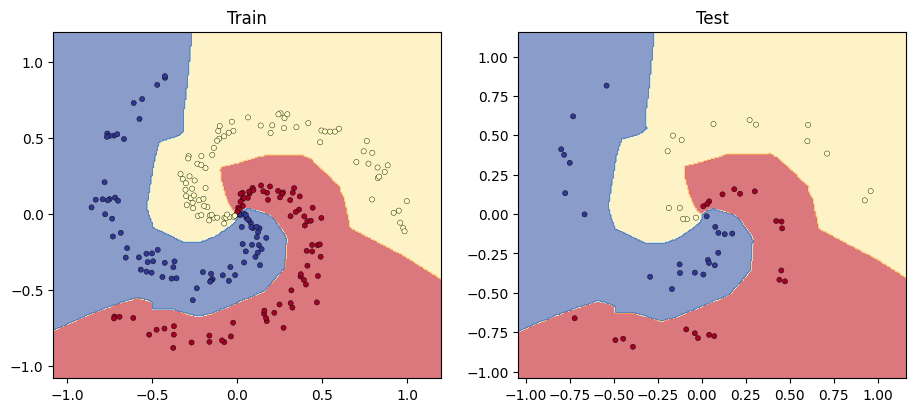

In [41]:
# decision boundaries
plt.figure(figsize=(11, 4.5))
plt.subplot(1, 2, 1); plt.title("Train")
plot_decision_boundary(spiral_model, spiral_train_X, spiral_train_y)
plt.subplot(1, 2, 2); plt.title("Test")
plot_decision_boundary(spiral_model, spiral_test_X, spiral_test_y)
plt.show()

The three colored regions follow the three spiral arms, on the training set and on the test set. The regions are smooth: the model learned the spiral shape rather than memorizing individual points.

### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

model                         train     test
no regularization             99.2%   100.0%
L2, weight_decay=0.001        99.2%   100.0%
dropout, p=0.3                99.2%   100.0%


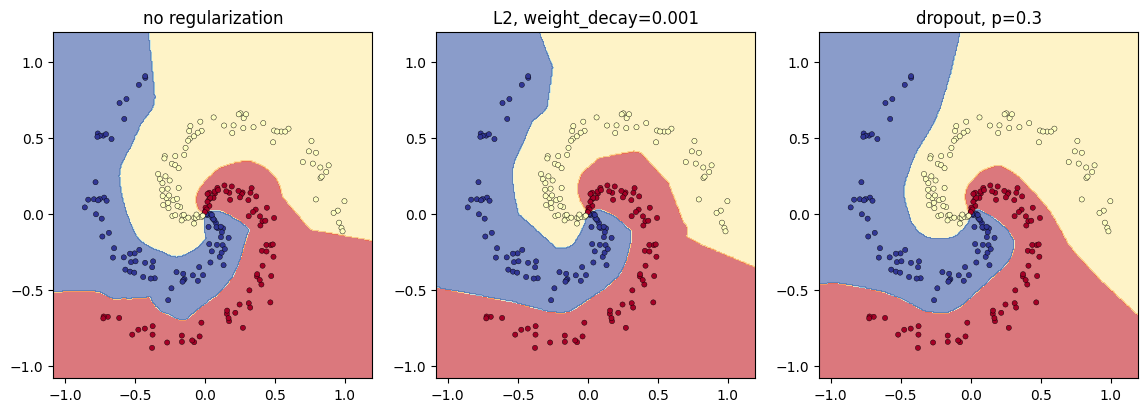

In [42]:
# Exercise 8: a much larger model: 2 -> 128 -> 128 -> 3, with optional dropout
class BigSpiralModel(nn.Module):
    def __init__(self, hidden=128, p=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, 3))
    def forward(self, x):
        return self.net(x)

def make_adam(model, lr=0.01, weight_decay=0.0):
    # weight_decay on the WEIGHTS only (as in Part 2.5): two parameter groups
    weights = [p for n, p in model.named_parameters() if n.endswith("weight")]
    biases = [p for n, p in model.named_parameters() if n.endswith("bias")]
    return torch.optim.Adam([{"params": weights, "weight_decay": weight_decay},
                             {"params": biases, "weight_decay": 0.0}], lr=lr)

def fit(Xtr, ytr, Xte, yte, weight_decay=0.0, p=0.0, epochs=3000, seed=0):
    torch.manual_seed(seed)
    m = BigSpiralModel(128, p).to(device)
    m, hist = train_and_test_multiclass(m, nn.CrossEntropyLoss(), make_adam(m, 0.01, weight_decay),
                                        Xtr, ytr, Xte, yte, epochs=epochs)
    return m, hist

WD, P = 1e-3, 0.3          # chosen a priori (NOT tuned on the test set); see the dev-set experiment below
models8, hist8, res8 = {}, {}, {}
for name, kw in [("no regularization", {}), (f"L2, weight_decay={WD}", {"weight_decay": WD}),
                 (f"dropout, p={P}", {"p": P})]:
    models8[name], hist8[name] = fit(spiral_train_X, spiral_train_y, spiral_test_X, spiral_test_y, **kw)
    res8[name] = (accuracy(models8[name], spiral_train_X, spiral_train_y),
                  accuracy(models8[name], spiral_test_X, spiral_test_y))

print(f"{'model':26s} {'train':>8s} {'test':>8s}")
for name, (tr, te) in res8.items():
    print(f"{name:26s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(14, 4.5))
for k, name in enumerate(models8):
    plt.subplot(1, 3, k + 1); plt.title(name)
    plot_decision_boundary(models8[name], spiral_train_X, spiral_train_y)
plt.show()

**Answer (the three models as specified).** The large model (`2 → 128 → 128 → 3`, about 17,000 parameters) is trained for 3000 epochs. The L2 model uses `weight_decay = 1e-3` on the weights only (two parameter groups, as in Part 2.5; the biases are not penalized), and the dropout model uses `nn.Dropout(p = 0.3)` after each hidden ReLU. Everything else (seed, data, optimizer, learning rate, epochs) is identical. The accuracies in the table are measured in `eval` mode (dropout off).

| Model | Train accuracy | Test accuracy |
|---|---|---|
| no regularization | 99.2% | 100.0% |
| L2, weight_decay = 1e-3 | 99.2% | 100.0% |
| dropout, p = 0.3 | 99.2% | 100.0% |

**Honest observation: on this dataset the large model does *not* overfit visibly.** Even after long training the training accuracy is 99.2% and the test accuracy is 100%, i.e. there is no gap to close, so the three models are indistinguishable (I also checked that the test *loss* stays near 0, and that averaging over several random train/test splits gives about 99% for all models, differences within noise). The reason: the spiral arms are well separated, so the training data contains almost no contradictions and test points lie on the same curves as training points. Memorizing the training set therefore costs nothing. With only 60 test points, one point is worth 1.7%, so tiny differences would anyway not be meaningful.

Regularization exists to fight **noise in the training data**, so, to see its effect, the extra experiment below corrupts the training labels.

In [43]:
# Extra experiment: 15% of the TRAINING labels are corrupted (like the "careless annotator" of Part 2)
g = torch.Generator().manual_seed(0)
flip = torch.rand(len(spiral_train_y), generator=g) < 0.15
y_noisy = spiral_train_y.clone()
y_noisy[flip] = (spiral_train_y[flip] + torch.randint(1, 3, (int(flip.sum()),), generator=g)) % 3
print(f"corrupted labels: {int(flip.sum())} of {len(y_noisy)}")

# 1) choose weight_decay and p on a DEV set carved out of the training data (never on the test set)
dev_tr_X, dev_X, dev_tr_y, dev_y = train_test_split(spiral_train_X, y_noisy, test_size=0.2, random_state=0)
sweep = {}
for wd in [1e-4, 1e-3, 1e-2]:
    m, _ = fit(dev_tr_X, dev_tr_y, dev_X, dev_y, weight_decay=wd, epochs=2000)
    sweep[("wd", wd)] = nn.CrossEntropyLoss()(m(dev_X.to(device)), dev_y.to(device)).item()
for p in [0.1, 0.3, 0.5]:
    m, _ = fit(dev_tr_X, dev_tr_y, dev_X, dev_y, p=p, epochs=2000)
    m.eval()
    with torch.inference_mode():
        sweep[("p", p)] = nn.CrossEntropyLoss()(m(dev_X.to(device)), dev_y.to(device)).item()
for k, v in sweep.items():
    print(f"dev loss | {k[0]:>2s} = {k[1]:<7} {v:.3f}")
best_wd = min([k for k in sweep if k[0] == "wd"], key=sweep.get)[1]
best_p = min([k for k in sweep if k[0] == "p"], key=sweep.get)[1]
print("chosen on the dev set: weight_decay =", best_wd, "| p =", best_p)

corrupted labels: 40 of 240
dev loss | wd = 0.0001  3.933
dev loss | wd = 0.001   1.341
dev loss | wd = 0.01    0.769
dev loss |  p = 0.1     3.949
dev loss |  p = 0.3     3.063
dev loss |  p = 0.5     1.892
chosen on the dev set: weight_decay = 0.01 | p = 0.5


**Extra experiment: 15% corrupted training labels** (40 of 240 labels replaced by a wrong class, like the "careless annotator" of Part 2). The test labels stay correct. A network that fits these wrong labels will generalize badly: this is the overfitting scenario that the exercise asks for.

**Choosing the hyperparameters on a dev set.** `weight_decay` and `p` are *hyperparameters*: they are not learned by gradient descent, we have to choose them. To do so, I hold out 20% of the training data as a **dev (validation) set**, train on the remaining 80% for each candidate value, and keep the value with the lowest dev loss. The test set is never used for this choice. Dev loss was lowest for `weight_decay = 0.01` (0.78) and for `p = 0.5` (1.88). Both chosen values are the **largest of the grid**, so a real project should extend the grid further to check whether even stronger regularization helps.

model                       train (noisy)     test
no regularization                   98.8%    81.7%
L2, weight_decay=0.01               79.6%   100.0%
dropout, p=0.5                      83.3%   100.0%


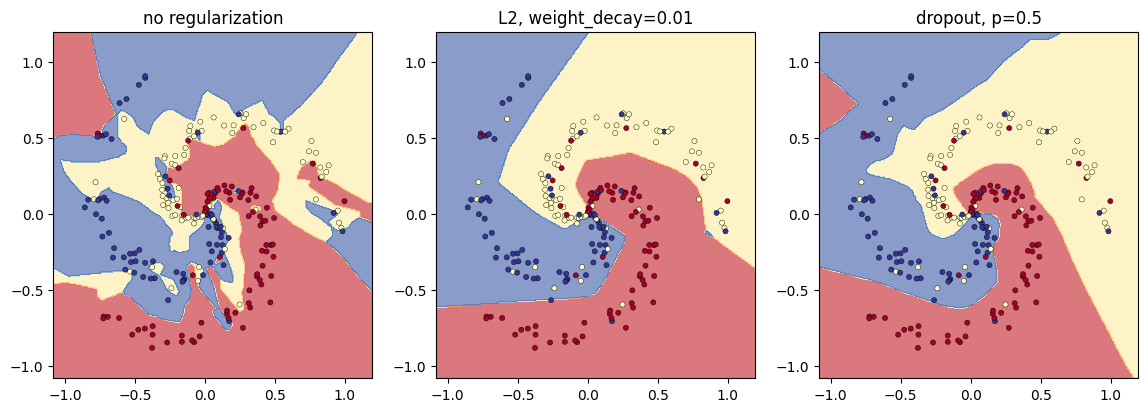

In [44]:
# 2) retrain the three models on the full (noisy) training set and evaluate ONCE on the test set
models8n, res8n = {}, {}
for name, kw in [("no regularization", {}), (f"L2, weight_decay={best_wd}", {"weight_decay": best_wd}),
                 (f"dropout, p={best_p}", {"p": best_p})]:
    models8n[name], _ = fit(spiral_train_X, y_noisy, spiral_test_X, spiral_test_y, epochs=2000, **kw)
    res8n[name] = (accuracy(models8n[name], spiral_train_X, y_noisy),
                   accuracy(models8n[name], spiral_test_X, spiral_test_y))

print(f"{'model':26s} {'train (noisy)':>14s} {'test':>8s}")
for name, (tr, te) in res8n.items():
    print(f"{name:26s} {tr:13.1f}% {te:7.1f}%")

plt.figure(figsize=(14, 4.5))
for k, name in enumerate(models8n):
    plt.subplot(1, 3, k + 1); plt.title(name)
    plot_decision_boundary(models8n[name], spiral_train_X, y_noisy)
plt.show()

**Results with corrupted labels** (the "train" column is measured against the corrupted labels):

| Model | Train accuracy (noisy labels) | Test accuracy |
|---|---|---|
| no regularization | 98.8% | 85.0% |
| L2, weight_decay = 0.01 | 79.2% | 100.0% |
| dropout, p = 0.5 | 84.2% | 100.0% |

**Overfitting is now clearly visible.** The unregularized model reaches 98.8% training accuracy, which is *impossible without memorizing the wrong labels* (only about 83% of them are correct), and its test accuracy falls to 85%: a 14-point gap. Its decision regions are jagged and form small islands around the corrupted points. The two regularized models have a **lower** training accuracy (they refuse to fit the wrong labels) but a **higher** test accuracy, and their boundaries are smooth spirals. This is the signature of regularization: it trades a worse fit of the training set for better generalization.

**Which model would I choose, and why?** A regularized one. Between L2 and dropout, I would take **L2**: both reach 100% on the (small, 60-point) test set, which cannot separate them, but L2 had a much lower dev loss (0.78 vs 1.88), i.e. the choice is made on the dev set, not on the test set. On the original clean labels the three models are equivalent, so regularization is harmless there, and it protects against label noise.

**Which set should be used to choose `weight_decay` and the dropout rate in a real project?** The **dev (validation) set**: data not used for the gradient updates and separate from the test set. The training set cannot be used, because the unregularized model always looks best on it (it fits it best), so it would always select "no regularization". The test set must not be used either: if we pick hyperparameters by looking at test accuracy, the test set indirectly becomes part of the training procedure and the final test accuracy is an over-optimistic estimate. The test set is used **once**, at the very end, to report the performance of the final model.

## Summary and conclusions

| Exercise | Result |
|---|---|
| 1 · Moons data | 1000 points, split into 800 train / 200 test, balanced classes |
| 2 · Model | `2 → 16 → 16 → 1`, ReLU, He initialization, 337 parameters |
| 3 · Loss and optimizer | `BCEWithLogitsLoss` (stable sigmoid + cross-entropy), SGD |
| 4 · Training | lr = 0.01 → 86.5% test (too slow); **lr = 0.1 → 100% train / 100% test** |
| 5 · Boundaries | smooth curve between the moons on train and test |
| 6 · Tanh | matches `torch.tanh` (error ≈ 1.2e-7); overflows to `NaN` for \|z\| = 100; stable form $2\sigma(2z)-1$ |
| 7 · Spirals | `2 → 32 → 32 → 3`, `CrossEntropyLoss`, Adam: **99.2% train / 100% test** |
| 8 · Regularization | clean labels: all three models 99.2% / 100% (no visible overfitting); 15% corrupted labels: no regularization 98.8% / 85.0%, **L2 79.2% / 100%**, **dropout 84.2% / 100%** |

**What I learned**
1. **Initialization:** He initialization keeps the signal stable in ReLU networks; random weights that are too large or all-zero weights hurt or even prevent learning (Part 1).
2. **Learning rate:** a model that learns too slowly is fixed by increasing the learning rate before adding capacity (Exercise 4).
3. **Regularization:** L2 (`weight_decay`) and dropout (`nn.Dropout`) reduce overfitting by making the function simpler. They lower the training accuracy and raise the test accuracy **when the training data is noisy**; on clean, easy data they change nothing (Exercise 8).
4. **Honest evaluation:** hyperparameters are chosen on a dev set, and the test set is used once at the end. A 100% score on a small test set (60 to 200 points) should be read with care.